# 03 · Re-ajuste de la política: comparativa de cinco optimizadores sobre la estructura y el objetivo finales

**Pregunta:** ¿qué optimizador encuentra mejores parámetros del policy, y con qué coste de cómputo?
**Diseño (idéntico para todos):** mismo espacio de parámetros continuos (`SPACE` en `src/optimize2.py`), 60 evaluaciones,
8 escenarios TUNE (2 por tipo: base, pico, rural-festivos, catálogo), misma función objetivo, semilla 2026. Cada evaluación ejecuta el **motor real**.
Optimizadores: Grid (rejilla gruesa barajada), Random, Sobol (QMC), Optuna/TPE (multivariado) y CMA-ES. Corrida **reanudable** con checkpoints atómicos
(`outputs/cache/`); sobrevivió a varias suspensiones de la laptop.

**Función objetivo (minimizar), por escenario**, referencia R = política "más barata inmediata":
`J = coste/coste_R + lead/lead_R + p95/p95_R + (10−RCP)/(10−RCP_R) + penalización dura por gate violado (+100 c/u)`, agregada con pesos de negocio
base 40 / pico 25 / rural-festivos 20 / catálogo 15. En la 2.ª corrida se suma una **penalización de dominancia sobre el starter** (con márgenes: coste −10 %, lead −8 %, p95 −1,5 %, RCP mayor).
CPU no entra en el tuning (es ruidosa); se mide aparte en serie.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")
ROOT = Path("..").resolve()                 # solucion/
REPO = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import plotstyle as PS, figs
PS.apply()
CSV, FIG = ROOT / "outputs" / "csvs", ROOT / "outputs" / "figs"
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
def show(fig):
    display(fig); plt.close(fig)

In [2]:
tr = pd.read_csv(CSV/"optimizers_trials.csv")
order = ["grid","random","sobol","tpe","cmaes"]
J_THR = float(tr.value.min()) * 1.01   # umbral comparable: 1 % por encima del mejor valor global
rows = []
for o in order:
    d = tr[tr.optimizer==o].sort_values("n").reset_index(drop=True)
    b = d.loc[d.value.idxmin()]
    reach = d[d.value <= J_THR]
    rows.append({"optimizador": o, "ensayos": len(d), "mejor_J": round(b.value,4), "ensayo_del_mejor": int(b.n)+1,
                 "wall_a_mejor_s": round(b.wall_s), "tiempo_medio_ensayo_s": round(d.trial_s.mean(),1),
                 "J_medio_top5": round(d.nsmallest(5, "value").value.mean(),4), "J_mediana_ensayos": round(d.value.median(),3),
                 "ensayos_hasta_J<=umbral": (int(reach.n.iloc[0])+1 if len(reach) else None),
                 "coste/ref": round(b.cost_ratio,3), "lead/ref": round(b.lead_ratio,3), "p95/ref": round(b.p95_ratio,3), "rcp": round(b.rcp,3),
                 "gates_violados_en_mejor": int(b.gate_bad)})
cmp_ = pd.DataFrame(rows)
cmp_.to_csv(CSV/"optimizers_comparison.csv", index=False)
print("umbral J =", round(J_THR, 4))
cmp_

umbral J = 3.6727


,optimizador,ensayos,mejor_J,ensayo_del_mejor,wall_a_mejor_s,tiempo_medio_ensayo_s,J_medio_top5,J_mediana_ensayos,ensayos_hasta_J<=umbral,coste/ref,lead/ref,p95/ref,rcp,gates_violados_en_mejor
0,grid,60,3.6471,4,58,16.0,3.6671,3.794,4,1.036,0.824,0.950,9.916,0
1,random,60,3.6534,7,114,15.7,3.6867,3.880,7,1.060,0.840,0.953,9.923,0
2,sobol,60,3.6364,4,64,16.2,3.6844,3.845,4,1.034,0.830,0.953,9.924,0
3,tpe,60,3.6603,28,449,16.0,3.6712,3.804,2,1.058,0.827,0.950,9.922,0
4,cmaes,60,3.6553,48,765,15.9,3.6660,3.739,16,1.042,0.829,0.952,9.924,0


> **Cómo leer la tabla.** `wall_a_mejor_s` mezcla la velocidad del optimizador **y** la de la máquina (cambió ×1,5 a 1,8 entre sesiones: ver `tiempo_medio_ensayo_s`).
> Por eso se reporta también `ensayo_del_mejor` y `ensayos_hasta_J<=umbral`, que no dependen de la máquina.

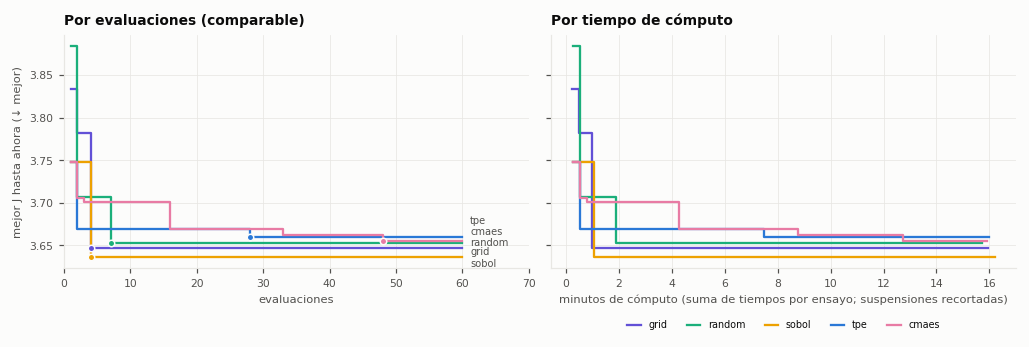

In [3]:
show(figs.opt_convergence(tr, order, name="opt_convergencia.png"))

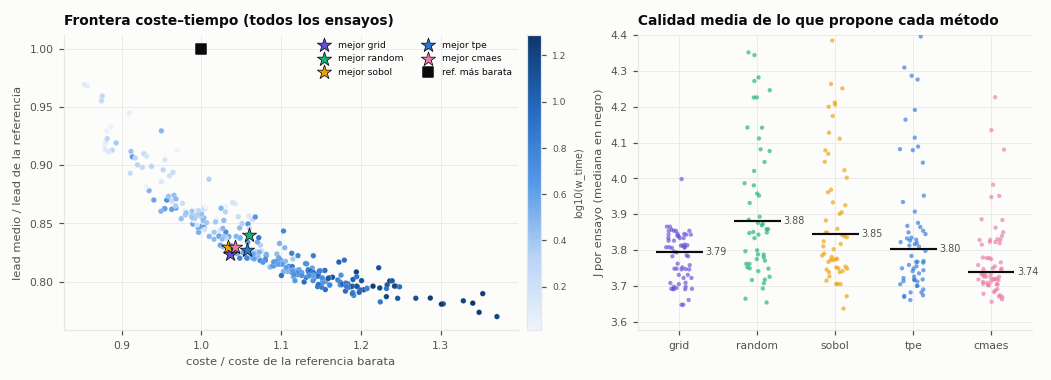

In [4]:
show(figs.opt_frontier(tr, order, name="opt_frontera_y_distribucion.png"))

### Sensibilidad: ¿qué parámetros importan?
Correlación de Spearman entre cada parámetro y J en los ensayos con todos los parámetros libres (random, sobol, tpe, cmaes).

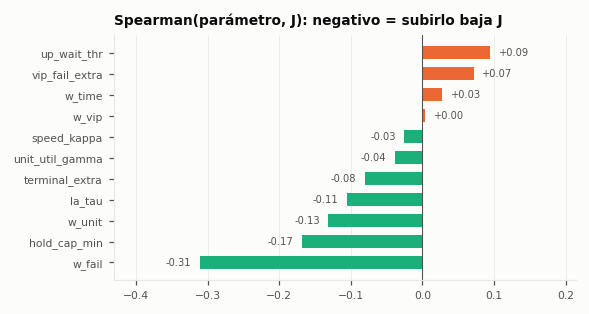

w_fail            -0.31
hold_cap_min      -0.17
w_unit            -0.13
la_tau            -0.11
terminal_extra    -0.08
unit_util_gamma   -0.04
speed_kappa       -0.03
w_vip              0.00
w_time             0.03
vip_fail_extra     0.07
up_wait_thr        0.09
Name: value, dtype: float64

In [5]:
pc = [c for c in tr.columns if c.startswith("p_")]
a = tr[tr.optimizer.isin(["random","sobol","tpe","cmaes"])]
sens = a[pc+["value"]].corr(method="spearman")["value"].drop("value").rename(lambda s: s[2:]).sort_values()
show(figs.opt_sensitivity(sens, name="opt_sensibilidad.png"))
sens.round(2)

### Qué muestra
El paisaje es casi plano: la diferencia entre el mejor y la mediana de cada método es pequeña frente a la variación **entre escenarios**; lo que mueve J es el intercambio
coste ↔ tiempo (`w_time`). Los métodos dirigidos (TPE, CMA-ES) y el cuasi-aleatorio (Sobol) rinden más por ensayo que Grid/Random. Como las diferencias entre los mejores son
pequeñas, **no se elige por J de TUNE**: los mejores de cada método pasan a robustez (notebook 04) con HOLD intacto y los casos de contrato.